# Explore generation experiments

This notebook walks through the four helpers in `json_storm.analysis`, using our
Qwen3.6 and GPT-6.1-Sol sweeps from 3 November 2026. We start with one experiment,
inspect its batches and candidates, then compare prompts and models.

Everything here is read-only: no model calls, MongoDB queries or experiment changes.
Accepted queries have passed parsing, target checks and persistence—not MongoDB execution.

## 1. Environment and experiment selection

Run `uv sync --locked` from the repository root and select its `.venv` Python kernel.
These examples require the original experiments in your local Yanex store
(default `~/.yanex/experiments`). On another machine, first copy/sync those experiments
or replace the IDs below. Explicit IDs keep our comparison reproducible.


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import yanex.results as yr
from IPython.display import display

from json_storm.analysis import (
    batch_table,
    candidate_table,
    runs_table,
    summarize_run,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)

# Each list is ordered p1 through p7.
sol_ids = ["57d6f1c3", "8e4ea30b", "6654acdc", "d78c69d7", "52a02a82", "af97d240", "9190cd17"]
qwen_ids = ["28b9755c", "669c89c4", "8adf1c41", "cf3ae5f7", "5f3c7b72", "4ef16c01", "e8999d55"]

sol = [yr.get_experiment(run_id) for run_id in sol_ids]
qwen = [yr.get_experiment(run_id) for run_id in qwen_ids]

experiment = sol[5]  # p6 contains our one persistence failure.
print(type(experiment).__name__, experiment.id, experiment.name, experiment.status)
print("Script:", experiment.script_path)


Experiment af97d240 3-generate-gpt61sol-p6 completed
Script: /Users/thomas/code/bondi-json-storm/experiments/generate.py


## 2. `summarize_run`: one experiment

The helper accepts the native Yanex `Experiment` and returns a dictionary. We turn
it into a one-row table for display. All four helpers require script basename
`generate.py`, so passing a schema experiment raises `ValueError`.

Yields are fractions: 0.95 means 95%. Missing measurements stay missing; they are
not zero. Metrics come from the latest logged step, falling back to the checkpoint
manifest only if no metrics were logged.


In [ ]:
summary = summarize_run(experiment)
summary_columns = [
    "experiment_id",
    "prompt_id",
    "model",
    "status",
    "metrics_source",
    "num_queries",
    "queries_parsed",
    "queries_accepted",
    "queries_persistence_failed",
    "accepted_yield",
    "unique_queries",
    "distinct_yield",
    "model_seconds",
]
display(pd.DataFrame([summary])[summary_columns].round(3))


{'accepted_yield': 0.95,
 'batch_size': 5,
 'batches_attempted': 4,
 'batches_count_mismatch': 0,
 'batches_parse_failed': 0,
 'cached_input_tokens': 0,
 'cached_input_tokens_per_accepted': 0.0,
 'cached_input_tokens_reported_calls': 4,
 'distinct_yield': 0.95,
 'estimated_cost_usd_per_accepted': None,
 'exact_duplicate_queries': 0,
 'examples_per_type': 0,
 'experiment_id': 'af97d240',
 'input_tokens': 5956,
 'input_tokens_per_accepted': 313.4736842105263,
 'input_tokens_reported_calls': 4,
 'manifest_status': 'completed',
 'metrics_source': 'logged',
 'model': 'chatgpt/gpt-6.1-sol',
 'model_calls_failed': 0,
 'model_elapsed_ms': 125119.11837337539,
 'model_parameters': {'reasoning_effort': 'low'},
 'model_seconds': 125.11911837337539,
 'name': '3-generate-gpt61sol-p6',
 'num_queries': 20,
 'output_tokens': 7998,
 'output_tokens_per_accepted': 420.94736842105266,
 'output_tokens_reported_calls': 4,
 'prompt_id': 'p6',
 'queries_accepted': 19,
 'queries_parse_failed': 0,
 'queries_pars

,experiment_id,prompt_id,model,status,metrics_source,num_queries,queries_parsed,queries_accepted,queries_persistence_failed,accepted_yield,unique_queries,distinct_yield,model_seconds
0,af97d240,p6,chatgpt/gpt-6.1-sol,completed,logged,20,20,19,1,0.95,19,0.95,125.119


## 3. `batch_table`: one row per model call

Sol p6 has four decoded responses. A decoded batch can still contain rejected
candidates, so batch success and candidate acceptance are different measurements.
Elapsed time is in milliseconds; usage fields are normalized from saved responses.


In [ ]:
batches = batch_table(experiment)
display(
    batches[
        [
            "batch_index",
            "requested_count",
            "outcome",
            "finish_reason",
            "elapsed_ms",
            "input_tokens",
            "output_tokens",
            "reasoning_tokens",
        ]
    ].round(1)
)


,batch_index,requested_count,outcome,finish_reason,elapsed_ms,input_tokens,output_tokens,reasoning_tokens
0,0,5,decoded,stop,36932.5,1489,2497,54
1,1,5,decoded,stop,29848.2,1489,1802,0
2,2,5,decoded,stop,26757.6,1489,1823,0
3,3,5,decoded,stop,31580.8,1489,1876,0


For contrast, Qwen p1 has three undecodable batches. Their requested slots are
known, but the number of actual candidates inside those malformed responses is not.
The error objects below preserve the original parser diagnostics.


In [1]:
qwen_batches = batch_table(qwen[0])
display(qwen_batches[["batch_index", "requested_count", "outcome", "parse_error"]])


NameError: name 'batch_table' is not defined

## 4. `candidate_table`: inspect individual outcomes

Each row represents one decoded candidate, identified by zero-based batch index
and position. No rows are invented for undecodable batches. Accepted candidates
also have a workload position and BONDI fingerprint.


In [ ]:
candidates = candidate_table(experiment)
display(
    candidates[
        [
            "batch_index",
            "position",
            "outcome",
            "accepted",
            "workload_position",
            "fingerprint",
        ]
    ].head(8)
)
display(candidates.groupby("outcome").size().rename("candidates").to_frame())

rejected = candidates.loc[~candidates["accepted"].eq(True)]
display(rejected[["batch_index", "position", "error", "persistence_error"]])
# Show the original projection behind this failure without rewriting the query.
display(rejected.iloc[0]["raw"]["projection"])


,batch_index,position,outcome,accepted,workload_position,fingerprint
0,0,0,accepted,True,0.0,740e8c239dac2e25da8e4deb43fd71110bcf5dc23ab66c5d6fa65b0113d3ee84
1,0,1,accepted,True,1.0,8900ed140a33e99c9fbc8ca281e4896586e5181e025bd4db65a5a6c6ecefc2c9
2,0,2,accepted,True,2.0,e344f1ed376d4c7faa25c8d2cfbe0c713cbf7b5b331146da8d07736be57fdc6c
3,0,3,accepted,True,3.0,78b1deccdcdb110dcdd77fdb2d33636d49a33d035fd3cc70a9906e4bec0c56b2
4,0,4,accepted,True,4.0,e15e3128acadf83fe27c36b840f58c2c90087487c05b2412d5854600525d8a94
5,1,0,accepted,True,5.0,ebca653b1e52f391f486ea10a17a7fe4381ee39ecf9ab2de6229818a2d3cfa9e
6,1,1,accepted,True,6.0,430bd126450d31f15fcd853ea626523e69d6b8c4901dd71dc6a4287997aaa1cc
7,1,2,accepted,True,7.0,0157f3772943bd749d39925143230483a4a5a48f6b0098307f0a2f8891f10fbd


,candidates
outcome,
accepted,19
persistence_failed,1


,batch_index,position,error,persistence_error
16,3,1,None,"{'type': 'TypeError', 'message': 'Object of type Regex is not JSON serializable'}"


{'_id': 0,
 'postId': 1,
 'title': 1,
 'body': 1,
 'comments': {'$elemMatch': {'text': {'$regex': '\\b(?:escape|encode|sanitize|validate)\\b',
    '$options': 'i'}}}}

This p6 candidate parsed, but a BSON regex inside its projection could not be
serialized by the installed BONDI version. Its raw query and error remain available.

Fingerprints also let us inspect repeated queries. Sol p4 has 20 accepted entries
but only 14 distinct fingerprints. All repeated occurrences are retained below;
we do not silently remove them from the measured yield.


In [ ]:
p4_candidates = candidate_table(sol[3])
accepted = p4_candidates.loc[p4_candidates["accepted"].eq(True)].dropna(subset=["fingerprint"])
duplicates = accepted.loc[accepted.duplicated("fingerprint", keep=False)]
display(
    duplicates[["batch_index", "position", "workload_position", "fingerprint"]].sort_values(
        ["fingerprint", "workload_position"]
    )
)


,batch_index,position,workload_position,fingerprint
1,0,1,1,42716c30a1d5e6e3d0a22798b9938bb59214cc92bbe9feb22acab3d9d7cfa706
11,2,1,11,42716c30a1d5e6e3d0a22798b9938bb59214cc92bbe9feb22acab3d9d7cfa706
16,3,1,16,42716c30a1d5e6e3d0a22798b9938bb59214cc92bbe9feb22acab3d9d7cfa706
0,0,0,0,a6a885c799efdd5748ee3b0c95196cdadf9819103f8532cc3d387040744a8e2c
10,2,0,10,a6a885c799efdd5748ee3b0c95196cdadf9819103f8532cc3d387040744a8e2c
15,3,0,15,a6a885c799efdd5748ee3b0c95196cdadf9819103f8532cc3d387040744a8e2c
4,0,4,4,c50c0222fa5d29bde64c5753adb02fd72acf0c57bba1260e0b8a8b8599210c87
13,2,3,13,c50c0222fa5d29bde64c5753adb02fd72acf0c57bba1260e0b8a8b8599210c87
3,0,3,3,d1865df8982c60c572bbde5538b38de1f64e6d8e76b6747108d014d29677ac1f
18,3,3,18,d1865df8982c60c572bbde5538b38de1f64e6d8e76b6747108d014d29677ac1f


## 5. `runs_table`: compare seven prompts

This helper stacks summaries without averaging repetitions or excluding failures.
First inspect the Sol sweep on its own. Distinct yield measures exact fingerprint
uniqueness within each run; it is not a measure of semantic diversity.


In [ ]:
sol_runs = runs_table(sol)
display(
    sol_runs[
        [
            "prompt_id",
            "queries_accepted",
            "unique_queries",
            "exact_duplicate_queries",
            "accepted_yield",
            "distinct_yield",
            "model_seconds",
            "output_tokens_per_accepted",
        ]
    ].round(3)
)


,prompt_id,queries_accepted,unique_queries,exact_duplicate_queries,accepted_yield,distinct_yield,model_seconds,output_tokens_per_accepted
0,p1,20,20,0,1.00,1.00,209.653,1062.950
1,p2,20,20,0,1.00,1.00,103.810,389.600
2,p3,20,17,3,1.00,0.85,42.942,139.600
3,p4,20,14,6,1.00,0.70,44.715,109.650
4,p5,20,20,0,1.00,1.00,255.672,1190.100
5,p6,19,19,0,0.95,0.95,125.119,420.947
6,p7,20,20,0,1.00,1.00,307.564,1468.500


## 6. Compare models for each prompt

Ordinary pandas operations are enough to build comparisons. Keep configuration
columns visible before interpreting differences. Both sweeps request 20 queries
with batch size 5 and the same schema. Reasoning settings and inference routes differ:
Sol uses low reasoning via subscription; Qwen runs locally with thinking off.


In [ ]:
runs = runs_table(sol + qwen)
display(
    runs[
        [
            "experiment_id",
            "prompt_id",
            "model",
            "batch_size",
            "num_queries",
            "target_collection",
            "model_parameters",
            "schema_sha256",
        ]
    ]
)
print("Distinct rendered schemas:", runs["schema_sha256"].nunique())

# Short labels are only for display; the original model column stays intact.
runs["model_label"] = runs["model"].map(
    {
        "chatgpt/gpt-6.1-sol": "Sol (low reasoning)",
        "ollama_chat/qwen3.6:latest": "Qwen (thinking off)",
    }
)
yield_by_prompt = runs.pivot(index="prompt_id", columns="model_label", values="accepted_yield")
display((100 * yield_by_prompt).round(1).rename_axis(columns=None))


,experiment_id,prompt_id,model,batch_size,num_queries,target_collection,model_parameters,schema_sha256
0,57d6f1c3,p1,chatgpt/gpt-6.1-sol,5,20,posts,{'reasoning_effort': 'low'},fc2063a83750ca9a80042939e7259fdb30a134b2217891ee8d01575402ae56f6
1,8e4ea30b,p2,chatgpt/gpt-6.1-sol,5,20,posts,{'reasoning_effort': 'low'},fc2063a83750ca9a80042939e7259fdb30a134b2217891ee8d01575402ae56f6
2,6654acdc,p3,chatgpt/gpt-6.1-sol,5,20,posts,{'reasoning_effort': 'low'},fc2063a83750ca9a80042939e7259fdb30a134b2217891ee8d01575402ae56f6
3,d78c69d7,p4,chatgpt/gpt-6.1-sol,5,20,posts,{'reasoning_effort': 'low'},fc2063a83750ca9a80042939e7259fdb30a134b2217891ee8d01575402ae56f6
4,52a02a82,p5,chatgpt/gpt-6.1-sol,5,20,posts,{'reasoning_effort': 'low'},fc2063a83750ca9a80042939e7259fdb30a134b2217891ee8d01575402ae56f6
5,af97d240,p6,chatgpt/gpt-6.1-sol,5,20,posts,{'reasoning_effort': 'low'},fc2063a83750ca9a80042939e7259fdb30a134b2217891ee8d01575402ae56f6
6,9190cd17,p7,chatgpt/gpt-6.1-sol,5,20,posts,{'reasoning_effort': 'low'},fc2063a83750ca9a80042939e7259fdb30a134b2217891ee8d01575402ae56f6
7,28b9755c,p1,ollama_chat/qwen3.6:latest,5,20,posts,{'think': False},fc2063a83750ca9a80042939e7259fdb30a134b2217891ee8d01575402ae56f6
8,669c89c4,p2,ollama_chat/qwen3.6:latest,5,20,posts,{'think': False},fc2063a83750ca9a80042939e7259fdb30a134b2217891ee8d01575402ae56f6
9,8adf1c41,p3,ollama_chat/qwen3.6:latest,5,20,posts,{'think': False},fc2063a83750ca9a80042939e7259fdb30a134b2217891ee8d01575402ae56f6


Distinct rendered schemas: 1


,Qwen (thinking off),Sol (low reasoning)
prompt_id,,
p1,25.0,100.0
p2,95.0,100.0
p3,100.0,100.0
p4,90.0,100.0
p5,25.0,100.0
p6,70.0,95.0
p7,25.0,100.0


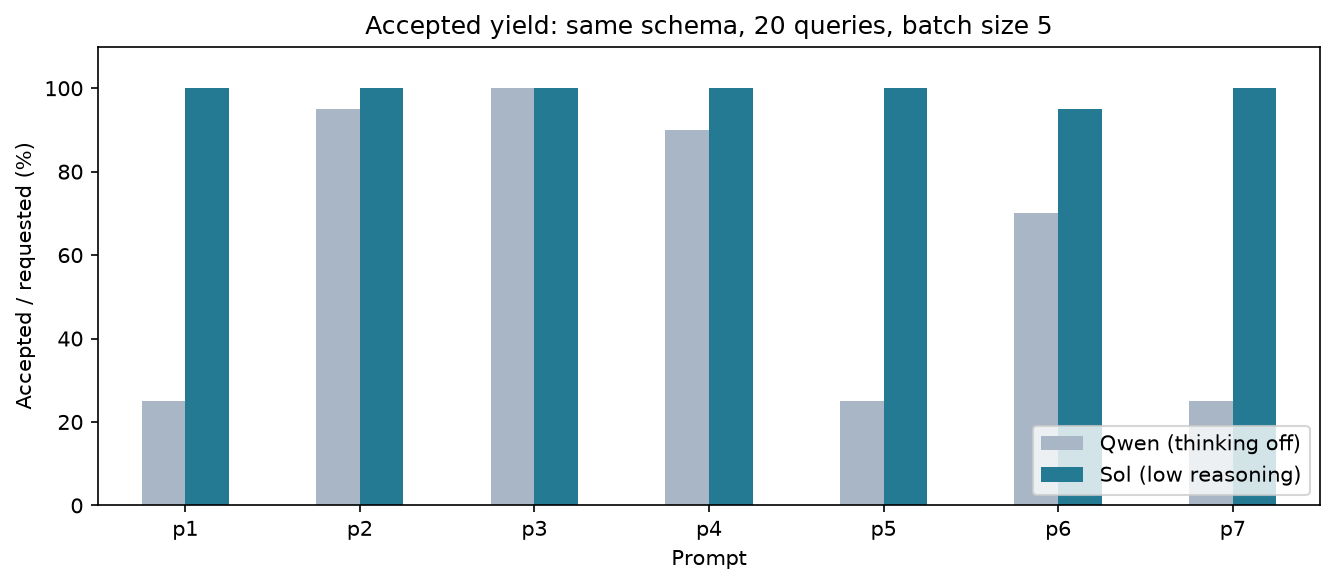

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
(100 * yield_by_prompt).plot.bar(ax=ax, rot=0, color=["#a9b6c6", "#247a92"])
ax.set(
    title="Accepted yield: same schema, 20 queries, batch size 5",
    xlabel="Prompt",
    ylabel="Accepted / requested (%)",
    ylim=(0, 110),
)
ax.legend(title=None, loc="lower right")
fig.tight_layout()
plt.show()


## 7. Compare one prompt across models

Filter first when your question concerns one prompt. Change `selected_prompt` to
explore another. The same pattern works for batch-size studies: select one prompt
and model, then sort by `batch_size`. These two sweeps have only batch size 5, so
they cannot tell us the effect of changing batch size.


In [ ]:
selected_prompt = "p1"
single_prompt = runs.loc[runs["prompt_id"].eq(selected_prompt)]
display(
    single_prompt[
        [
            "model_label",
            "batch_size",
            "queries_accepted",
            "unique_queries",
            "model_seconds",
            "seconds_per_accepted",
            "output_tokens_per_accepted",
            "output_tokens_reported_calls",
            "batches_attempted",
        ]
    ].round(2)
)


,model_label,batch_size,queries_accepted,unique_queries,model_seconds,seconds_per_accepted,output_tokens_per_accepted,output_tokens_reported_calls,batches_attempted
0,Sol (low reasoning),5,20,20,209.65,10.48,1062.95,4,4
7,Qwen (thinking off),5,5,5,239.59,47.92,3820.20,4,4


## 8. Interpret the comparison

- Sol accepted 139/140 queries; Qwen accepted 86/140. Acceptance still does not prove
  that MongoDB can execute a query or that it returns documents.
- Sol has repetitions in p3/p4, which acceptance alone hides.
- Time per accepted query includes time spent on failed responses. Token ratios
  are only as complete as the reported-call coverage; providers use different tokenizers.
- One run per prompt is descriptive evidence, not a replicated model ranking.
- `pivot` intentionally raises if you later select multiple runs per model/prompt.
  Keep those replicate IDs and choose an explicit aggregation rather than silently
  averaging them. Pooled yield and mean run yield answer different questions.

For interrupted runs, an empty candidate table can mean either an empty artifact
or a missing one: inspect `table.attrs["artifact_available"]`. Batch tables mark
missing artifacts per row. Call `experiment.refresh()` before rereading a live run.

Next, try changing the experiment selection and the columns displayed. Plotting and
saving reports remain notebook responsibilities; the four helpers only read data.
